In [1]:
#Abigail Birnbaum (abigail.birnbaum@pnnl.gov)
#Last updated 2026-10-12
#Create CSVs converting 1/16-degree grid cells to basin scale (NCAR delineations)

# Import Statements

In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from calendar import monthrange
import time

import xarray as xr
import rioxarray as rio
import rasterio
from rasterio.enums import Resampling
import shapely

# Define Methods

In [3]:
def create_grid(grid_dist,grid_bounds,crs_ref):
    """Function to create geodataframe of polygon boxes representing a uniform spatial grid.
    Inputs:
    grid_dist: spatial resolution of grid cell
    grid_cells: geodataframe containing grid as point values, assume lat/lon represent centers of grid cells
    crs_ref: geographic coordinate system to apply to the outputed grid. 

    Helpful guide when originally developing thiscode for a different project: 
    https://james-brennan.github.io/posts/fast_gridding_geopandas/
    Outputs:
    cells: geodataframe of uniform polygon boxes representing a spatial grid.
    """
    
    grid_half = grid_dist/2 #half of the desired spatial resolution
    #set min and max lat/lon for grid
    xmin = grid_bounds[0] - grid_half; xmax = grid_bounds[2] + grid_half
    ymin = grid_bounds[1] - grid_half; ymax = grid_bounds[3] + grid_half

    #get number of cells and cell size in each direction (x,y)
    n_cells_x = int(np.round(((xmax-xmin)/grid_dist))); n_cells_y = int(np.round((ymax-ymin)/grid_dist));
    cell_size_x = (xmax-xmin)/n_cells_x; cell_size_y = (ymax-ymin)/n_cells_y

    #print to check everything is correct
    print('# cells lon: ',n_cells_x); print('# cells lat: ',n_cells_y); print('cell size lon: ',cell_size_x); print('cell size lat: ',cell_size_y)
    
    grid_cells_basin = [] #empty list to store grid cells
    for x0 in np.arange(xmin,xmax,cell_size_x):
        for y0 in np.arange(ymin,ymax,cell_size_y):
            x1 = x0+cell_size_x
            y1 = y0+cell_size_y
            grid_cells_basin.append(shapely.geometry.box(x0,y0,x1,y1)) #box with bounds x0,y0,x1,y1
    cells = gpd.GeoDataFrame(grid_cells_basin,columns=['geometry'],crs=crs_ref) #convert list of polygon boxes into geodataframe
    return cells #return

# Specify HUC or PFAF to create files for

In [ ]:
#### Set reference and projected CRS ####
crs_ref = 'epsg:4326' #specify geographic CRS to use for all analysis
crs_proj = 'epsg:5070' #NAD83 CONUS Albers equal area- US CONUS

#specify region
reg_sel = 'huc01' # HUC 01-18, pfaf 71, 72, 73, 75, 77, 78
pwp = '/gcfs/projects/foresight/hydrology/'
basin_path = 'abirn_vic/input_data/ncar_region_shapefiles/'
#filter shapefile to selected HUC-02 or PFAF region
#basin_shp = basins_shp[basins_shp.region==reg_sel].reset_index().drop(columns=['index']) #filter to just region we're looking at
basin_shp = gpd.read_file(basin_path+'region_'+reg_sel+'.shp')
basin_shp = basin_shp.to_crs(crs_ref) #make sure we're in the correct CRS
basin_shp = basin_shp.filter(['HUCIDX','HUC_SRC','ToHUC','geometry']) #96715 unique
basin_shp['basin'] = basin_shp['HUCIDX'].copy()
basin_shp_proj = basin_shp.to_crs(crs_proj) #EPSG 5070
basin_shp_proj['basin_area_m2'] = basin_shp_proj.area

# Define Grids: 1/16-degree for parameters

In [ ]:
#DATA PATHS
domain_path = pwp+'abirn_vic/input_data/domain_by_huc2/' #have confirmed that bounds of domain contain all of the basin shape
grid_0625_domain = xr.open_dataset(domain_path+'namerica_domain_'+reg_sel+'.nc')

# Create 1/16-degree grid (based on VIC-Global domain)

In [10]:
#### Read in data ####
grid_0625 = grid_0625_domain[['lat','lon']].to_dataframe().reset_index()
grid_0625 = gpd.GeoDataFrame(grid_0625,geometry=gpd.points_from_xy(grid_0625.lon,grid_0625.lat),crs=crs_ref) #convert grid cells to GDF

##### Create grid ####
grid_0625_res = 1./16 #desired spatial resolution is 1/16 degree
basin_min_lon, basin_min_lat, basin_max_lon, basin_max_lat = basin_shp.total_bounds #get bounds of region
#add in a buffer
grid_0625_min_lon = basin_min_lon-grid_0625_res;
grid_0625_min_lat = basin_min_lat-grid_0625_res;
grid_0625_max_lon = basin_max_lon+grid_0625_res;
grid_0625_max_lat = basin_max_lat+grid_0625_res;
grid_0625 = grid_0625[(grid_0625.lon>=grid_0625_min_lon)  #clip grid cells to bounds of region
                    & (grid_0625.lon<=grid_0625_max_lon) 
                    & (grid_0625.lat>=grid_0625_min_lat) 
                    & (grid_0625.lat<=grid_0625_max_lat)]
grid_0625_bounds = [grid_0625.lon.min(),grid_0625.lat.min(),grid_0625.lon.max(),grid_0625.lat.max()]
grid_0625_cells = create_grid(grid_0625_res,grid_0625_bounds,crs_ref) #create grid - polygons

#### Calculate fractional area of grid cell and basin  ####
grid_0625_cells = grid_0625_cells.sjoin(grid_0625,predicate='contains') #associate each grid cell box with its lat/lon centroid from grid_cells
grid_0625_cells = grid_0625_cells.drop(['index_right'],axis=1)

# cells lon:  112
# cells lat:  117
cell size lon:  0.0625
cell size lat:  0.0625


# Merge 1/16-deg grid with basin (HUC-12 or merit)

In [14]:
# convert to projected coordinate system for more accurate calculations
grid_0625_cells_prj = grid_0625_cells.to_crs(crs_proj) #project grid cells

# calculations for grid/basin
grid_0625_cells_prj['grid_0625_area_m2'] = grid_0625_cells_prj.area #calculate area of each grid cell

#calculate intersection between grid cells and basins
fract_cells_grid_0625_basin = grid_0625_cells_prj.overlay(basin_shp_proj,how='intersection',keep_geom_type=False)
fract_cells_grid_0625_basin['area_in_basin'] = fract_cells_grid_0625_basin.area #calculate each fractional cell's area in each basin
fract_cells_grid_0625_basin['fract_basin_area'] = fract_cells_grid_0625_basin['area_in_basin']/fract_cells_grid_0625_basin['basin_area_m2']                                          
fract_cells_grid_0625_basin['fract_grid_0625_area'] = fract_cells_grid_0625_basin['area_in_basin']/fract_cells_grid_0625_basin['grid_0625_area_m2'] #calculate fraction of grid cell 
fract_cells_grid_0625_basin = fract_cells_grid_0625_basin.filter(['lon','lat','basin','grid_0625_area_m2',
                                                      'basin_area_m2','area_in_basin','fract_basin_area','fract_grid_0625_area','geometry']) #filter just to the columns we need
#convert back to lat/lon coordinates (crs ref)
fract_cells_grid_0625_basin = fract_cells_grid_0625_basin.to_crs(crs_ref)
fract_cells_grid_0625_basin['basin'] = fract_cells_grid_0625_basin['basin'].astype(str)

## check

In [15]:
#make sure all basins sum to 1
print(fract_cells_grid_0625_basin.groupby(['basin'])['fract_basin_area'].sum().reset_index().sort_values(by='fract_basin_area').head(1))
print(fract_cells_grid_0625_basin.groupby(['basin'])['fract_basin_area'].sum().reset_index().sort_values(by='fract_basin_area').tail(1))

             basin  fract_basin_area
1085  010500040903               1.0
            basin  fract_basin_area
976  010500021104               1.0


<Axes: >

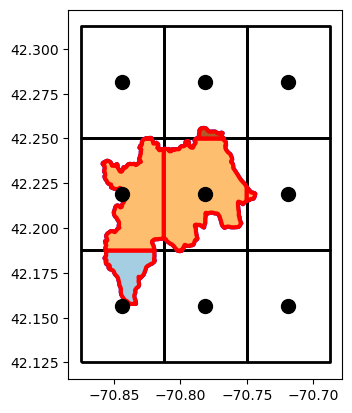

In [16]:
basin_list = basin_shp.basin.unique()
basin_select = basin_list[0]
fig,ax = plt.subplots(1,1)
basin_shp[basin_shp.basin==basin_select].boundary.plot(ax=ax,color='b',lw=3,label='basin boundary')
fract_cells_grid_0625_basin[fract_cells_grid_0625_basin.basin==basin_select].plot(ax=ax,lw=3,column='lat',cmap='Paired',edgecolor='r',zorder=2)
lon_vals = fract_cells_grid_0625_basin[fract_cells_grid_0625_basin.basin==basin_select]['lon'].unique()
lat_vals = fract_cells_grid_0625_basin[fract_cells_grid_0625_basin.basin==basin_select]['lat'].unique()
xl = ax.get_xlim(); yl=ax.get_ylim();
grid_0625_cells[(grid_0625_cells.lon.isin(lon_vals))
    & (grid_0625_cells.lat.isin(lat_vals))].boundary.plot(ax=ax,color='k',lw=2,zorder=1)
grid_0625[(grid_0625.lon.isin(lon_vals)) & 
    (grid_0625.lat.isin(lat_vals))].plot(ax=ax,color='k',markersize=100,zorder=2,label='grid cell centroid - overlap w/ basin')

# Save Output

In [17]:
len(fract_cells_grid_0625_basin.basin.unique())

1943

In [ ]:
#just basins that have full coverage
save_path = pwp+'abirn_vic/input_data/grid_cell_conversions/grid_0625deg_basin/'
fract_cells_grid_0625_basin.drop(columns=['geometry']).to_csv(save_path+'fract_cells_grid_0625_basin_'+reg_sel+'.csv',index=False)